--- Start (LSTM Deep Learning) - FINAL ATTEMPT ---
Train Shape: (17631, 30, 21)
Training... (Now the Loss will be very small, e.g., 0.02)
Epoch 1/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 19s 177ms/step - loss: 0.0582 - val_loss: 0.0333 - learning_rate: 0.0010
Epoch 2/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 208ms/step - loss: 0.0319 - val_loss: 0.0242 - learning_rate: 0.0010
Epoch 3/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 202ms/step - loss: 0.0226 - val_loss: 0.0189 - learning_rate: 0.0010
Epoch 4/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - loss: 0.0193 - val_loss: 0.0161 - learning_rate: 0.0010
Epoch 5/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 13s 156ms/step - loss: 0.0184 - val_loss: 0.0145 - learning_rate: 0.0010
Epoch 6/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 15s 182ms/step - loss: 0.0169 - val_loss: 0.0147 - learning_rate: 0.0010
Epoch 7/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - loss: 0.0180 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 8/60
80/80 ━━━━━━━━━━━━━━━━━━━━ 14s 175ms/step - loss: 0.0167 - val_loss: 0.015

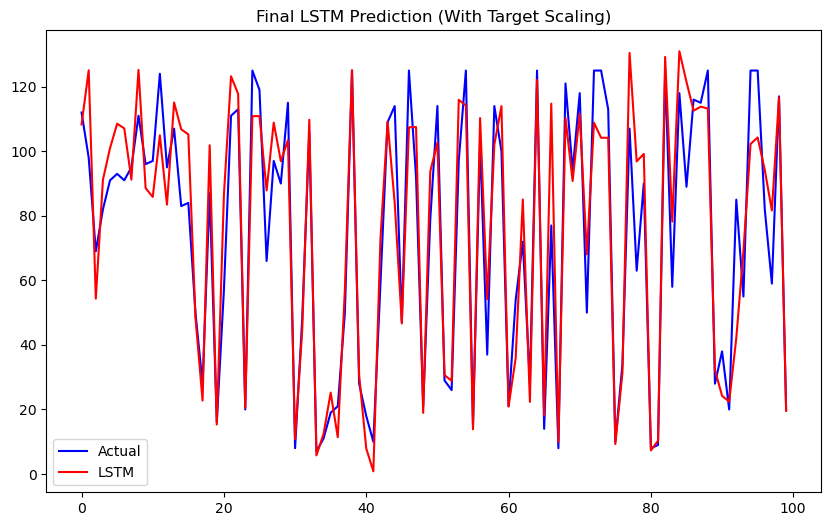

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# --- CONFIGURATION ---
SEQUENCE_LENGTH = 30 
file_id = 'FD001'

print(f"--- Start (LSTM Deep Learning) - FINAL ATTEMPT ---")

# 1. Load Data
train_df = pd.read_csv(f'../data/processed/train_{file_id}_processed.csv')
test_df = pd.read_csv(f'../data/processed/test_{file_id}_processed.csv')
rul_df = pd.read_csv(f'../data/raw/RUL_{file_id}.txt', header=None, names=['RUL_actual'])

# RUL Clipping
train_df['RUL'] = train_df['RUL'].clip(upper=125)
y_true = rul_df['RUL_actual'].clip(upper=125)

# 2. FEATURE SELECTION AND NORMALIZATION
features_cols = [c for c in train_df.columns if c not in ['unit_nr', 'time_cycles', 'RUL']]
scaler = MinMaxScaler()
train_df[features_cols] = scaler.fit_transform(train_df[features_cols])
test_df[features_cols] = scaler.transform(test_df[features_cols])

# 3. GENERATE SEQUENCES
def gen_sequence(id_df, seq_length, seq_cols):
    data_matrix = id_df[seq_cols].values
    num_elements = data_matrix.shape[0]
    for start, stop in zip(range(0, num_elements-seq_length), range(seq_length, num_elements)):
        yield data_matrix[start:stop, :]

def gen_labels(id_df, seq_length, label):
    data_matrix = id_df[label].values
    num_elements = data_matrix.shape[0]
    return data_matrix[seq_length:num_elements, :]

# Generate X (Features)
seq_gen = (list(gen_sequence(train_df[train_df['unit_nr']==id], SEQUENCE_LENGTH, features_cols)) 
           for id in train_df['unit_nr'].unique())
seq_array = np.concatenate(list(seq_gen)).astype(np.float32)

# Generate Y (Labels)
label_gen = [gen_labels(train_df[train_df['unit_nr']==id], SEQUENCE_LENGTH, ['RUL']) 
             for id in train_df['unit_nr'].unique()]
label_array = np.concatenate(label_gen).astype(np.float32)

# --- CRITICAL CHANGE 1: NORMALIZE THE TARGET (TARGET SCALING) ---
# The network learns much better if the output is between 0 and 1
label_array = label_array / 125.0 

print(f"Train Shape: {seq_array.shape}") 

# 4. BUILD MODEL (Same as before)
model = Sequential()
model.add(Input(shape=(SEQUENCE_LENGTH, len(features_cols))))
model.add(LSTM(units=100, return_sequences=True))
model.add(Dropout(0.2)) 
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=1, activation='linear')) # Now predicts between 0 and 1

model.compile(loss='mean_squared_error', optimizer='adam')

# 5. TRAIN
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

print("Training... (Now the Loss will be very small, e.g., 0.02)")
history = model.fit(seq_array, label_array, 
                    epochs=60, # 60 epochs is usually enough with scaling
                    batch_size=200, 
                    validation_split=0.1, 
                    verbose=1,
                    callbacks=[early_stop, reduce_lr])

# 6. EVALUATE
seq_array_test_last = [test_df[test_df['unit_nr']==id][features_cols].values[-SEQUENCE_LENGTH:] 
                       for id in test_df['unit_nr'].unique() if len(test_df[test_df['unit_nr']==id]) >= SEQUENCE_LENGTH]
seq_array_test_last = np.asarray(seq_array_test_last).astype(np.float32)

# Predict (The result will come between 0 and 1)
y_pred_scaled = model.predict(seq_array_test_last)

# --- CRITICAL CHANGE 2: DE-NORMALIZE THE PREDICTION ---
# Multiply by 125 to get back to real cycles
y_pred = y_pred_scaled * 125.0

# Prepare y_true
y_true_valid = []
ids_test = test_df['unit_nr'].unique()
for id_nr in ids_test:
    if len(test_df[test_df['unit_nr']==id_nr]) >= SEQUENCE_LENGTH:
        y_true_valid.append(y_true.iloc[id_nr-1]) 
y_true_valid = np.array(y_true_valid)

# Metrics
rmse = np.sqrt(mean_squared_error(y_true_valid, y_pred))
r2 = r2_score(y_true_valid, y_pred)

print(f"\n--- FINAL RESULT (LSTM) ---")
print(f"RMSE: {rmse:.2f} (Expected: < 18.00)")
print(f"R2: {r2:.4f}")

plt.figure(figsize=(10,6))
plt.plot(y_true_valid, label='Actual', color='blue')
plt.plot(y_pred, label='LSTM', color='red')
plt.title(f'Final LSTM Prediction (With Target Scaling)')
plt.legend()
plt.show()

--- START FINAL LOOP (LSTM) ---

---> Processing FD001...
Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 208ms/step - loss: 0.0627 - val_loss: 0.0318 - learning_rate: 0.0010
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 215ms/step - loss: 0.0316 - val_loss: 0.0235 - learning_rate: 0.0010
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - loss: 0.0236 - val_loss: 0.0238 - learning_rate: 0.0010
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 13s 165ms/step - loss: 0.0193 - val_loss: 0.0239 - learning_rate: 0.0010
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 15s 191ms/step - loss: 0.0187 - val_loss: 0.0156 - learning_rate: 0.0010
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 249ms/step - loss: 0.0180 - val_loss: 0.0156 - learning_rate: 0.0010
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - loss: 0.0170 - val_loss: 0.0159 - learning_rate: 0.0010
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 208ms/step - loss: 0.0166 - val_loss: 0.0150 - learning_rate: 0.0010
Epoch 9/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 211ms/step -

,Dataset,RMSE,R2
0,FD001,14.491339,0.869230
1,FD002,16.611473,0.849099
2,FD003,13.773281,0.876333
3,FD004,20.910246,0.760755


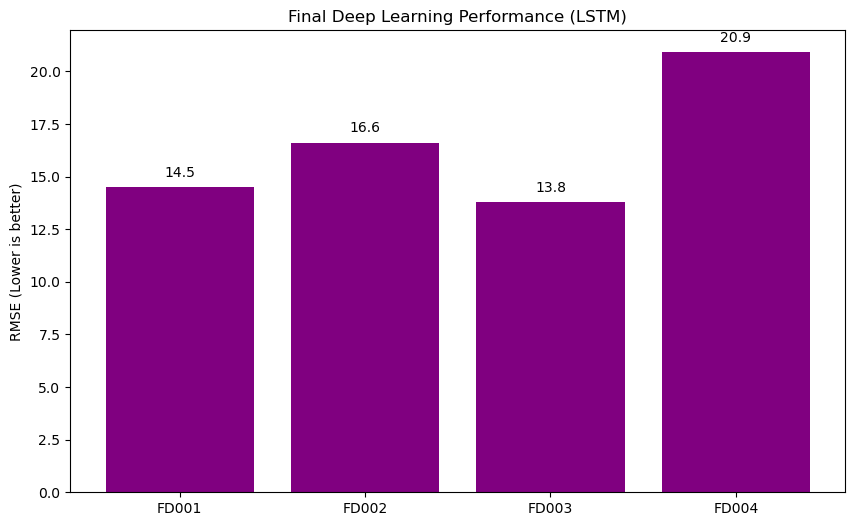

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import os

# Suppress annoying TensorFlow warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# --- CONFIGURATION ---
datasets = ['FD001', 'FD002', 'FD003', 'FD004']
base_path = '../data' 
SEQUENCE_LENGTH = 30
results_lstm = []

print(f"--- START FINAL LOOP (LSTM) ---")

for file_id in datasets:
    # 1. Clear Session (Essential for loops in Keras/TF)
    tf.keras.backend.clear_session()
    print(f"\n---> Processing {file_id}...")

    # 2. Load Data
    try:
        train_df = pd.read_csv(f'{base_path}/processed/train_{file_id}_processed.csv')
        test_df = pd.read_csv(f'{base_path}/processed/test_{file_id}_processed.csv')
        rul_df = pd.read_csv(f'{base_path}/raw/RUL_{file_id}.txt', header=None, names=['RUL_actual'])
    except FileNotFoundError:
        print(f"Data not found for {file_id}. Skipping.")
        continue

    # 3. Feature Engineering (Clipping)
    train_df['RUL'] = train_df['RUL'].clip(upper=125)
    y_true_raw = rul_df['RUL_actual'].clip(upper=125)

    # 4. Normalization (Features)
    features_cols = [c for c in train_df.columns if c not in ['unit_nr', 'time_cycles', 'RUL']]
    scaler = MinMaxScaler()
    train_df[features_cols] = scaler.fit_transform(train_df[features_cols])
    test_df[features_cols] = scaler.transform(test_df[features_cols])

    # 5. Generate Sequences (Internal helper functions)
    def gen_sequence(id_df, seq_length, seq_cols):
        data_matrix = id_df[seq_cols].values
        num_elements = data_matrix.shape[0]
        for start, stop in zip(range(0, num_elements-seq_length), range(seq_length, num_elements)):
            yield data_matrix[start:stop, :]

    def gen_labels(id_df, seq_length, label):
        data_matrix = id_df[label].values
        num_elements = data_matrix.shape[0]
        return data_matrix[seq_length:num_elements, :]

    # Generate Train X and Y
    seq_gen = (list(gen_sequence(train_df[train_df['unit_nr']==id], SEQUENCE_LENGTH, features_cols)) 
               for id in train_df['unit_nr'].unique())
    # Concat might fail if the list is empty (very short engines), but in C-MAPSS this is rare
    seq_array = np.concatenate(list(seq_gen)).astype(np.float32)

    label_gen = [gen_labels(train_df[train_df['unit_nr']==id], SEQUENCE_LENGTH, ['RUL']) 
                 for id in train_df['unit_nr'].unique()]
    label_array = np.concatenate(label_gen).astype(np.float32)

    # *** CRITICAL: Target Scaling ***
    label_array = label_array / 125.0

    # 6. Build Model
    model = Sequential()
    model.add(Input(shape=(SEQUENCE_LENGTH, len(features_cols))))
    # 
    model.add(LSTM(units=100, return_sequences=True))
    model.add(Dropout(0.2)) 
    model.add(LSTM(units=50, return_sequences=False))
    model.add(Dropout(0.2))
    model.add(Dense(units=1, activation='linear'))

    model.compile(loss='mean_squared_error', optimizer='adam')

    # 7. Train
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=0)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=0)

    # Fewer epochs for complex ones so it doesn't take forever in class, 
    # but early_stop should handle this.
    history = model.fit(seq_array, label_array, 
                        epochs=40, # 40 is usually enough
                        batch_size=200, 
                        validation_split=0.1, 
                        verbose=1, # Change to 0 if you want less text
                        callbacks=[early_stop, reduce_lr])

    # 8. Evaluate on Test
    seq_array_test_last = [test_df[test_df['unit_nr']==id][features_cols].values[-SEQUENCE_LENGTH:] 
                           for id in test_df['unit_nr'].unique() if len(test_df[test_df['unit_nr']==id]) >= SEQUENCE_LENGTH]
    
    if len(seq_array_test_last) == 0:
        print("Error: No test engine has sufficient length.")
        continue

    seq_array_test_last = np.asarray(seq_array_test_last).astype(np.float32)

    # Predict and De-normalize
    y_pred_scaled = model.predict(seq_array_test_last, verbose=0)
    y_pred = y_pred_scaled * 125.0

    # Align y_true
    y_true_valid = []
    ids_test = test_df['unit_nr'].unique()
    for id_nr in ids_test:
        if len(test_df[test_df['unit_nr']==id_nr]) >= SEQUENCE_LENGTH:
            # -1 in index because IDs start at 1
            y_true_valid.append(y_true_raw.iloc[id_nr-1]) 
    
    y_true_valid = np.array(y_true_valid)

    # Metrics
    rmse = np.sqrt(mean_squared_error(y_true_valid, y_pred))
    r2 = r2_score(y_true_valid, y_pred)
    
    results_lstm.append({
        'Dataset': file_id,
        'RMSE': rmse,
        'R2': r2
    })
    
    print(f"   -> {file_id} Finished. RMSE: {rmse:.2f}")

# --- FINAL PRESENTATION ---
results_df = pd.DataFrame(results_lstm)
print("\n--- FINAL SUMMARY (LSTM) ---")
try:
    display(results_df)
except:
    print(results_df)

# Final Comparative Plot
plt.figure(figsize=(10,6))
plt.bar(results_df['Dataset'], results_df['RMSE'], color='purple')
plt.title('Final Deep Learning Performance (LSTM)')
plt.ylabel('RMSE (Lower is better)')
# Add labels
for i, v in enumerate(results_df['RMSE']):
    plt.text(i, v + 0.5, f"{v:.1f}", ha='center')
plt.show()